In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('data_science_job.csv')

In [3]:
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,NaN,NaN,36.0,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15.0,50-99,Pvt Ltd,47.0,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5.0,NaN,NaN,83.0,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,0.0,NaN,Pvt Ltd,52.0,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,20.0,50-99,Funded Startup,8.0,0.0


In [4]:
(df.isna().sum() / df.shape[0]) * 100

enrollee_id                0.000000
city                       0.000000
city_development_index     2.500261
gender                    23.530640
relevent_experience        0.000000
enrolled_university        2.014824
education_level            2.401086
major_discipline          14.683161
experience                 0.339284
company_size              30.994885
company_type              32.049274
training_hours             3.998330
target                     0.000000
dtype: float64

In [5]:
cols = [col for col in df.columns if (df[col].isna().mean() <= 0.05 and df[col].isna().mean() > 0)]

In [6]:
cols

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

In [7]:
new_df = df[cols]

In [8]:
new_df.dropna(inplace= True)

C:\Users\gpava\AppData\Local\Temp\ipykernel_11740\4135980325.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df.dropna(inplace= True)


In [9]:
new_df.shape[0]

17182

In [10]:
df.shape[0]

19158

In [11]:
new_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 17182 entries, 0 to 19157
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   city_development_index  17182 non-null  float64
 1   enrolled_university     17182 non-null  object 
 2   education_level         17182 non-null  object 
 3   experience              17182 non-null  float64
 4   training_hours          17182 non-null  float64
dtypes: float64(3), object(2)
memory usage: 805.4+ KB


In [12]:
str(df['city_development_index'].dtype).startswith('float')

True

In [13]:
cols = [col for col in new_df.columns if (str(df[col].dtype)).startswith('float')]

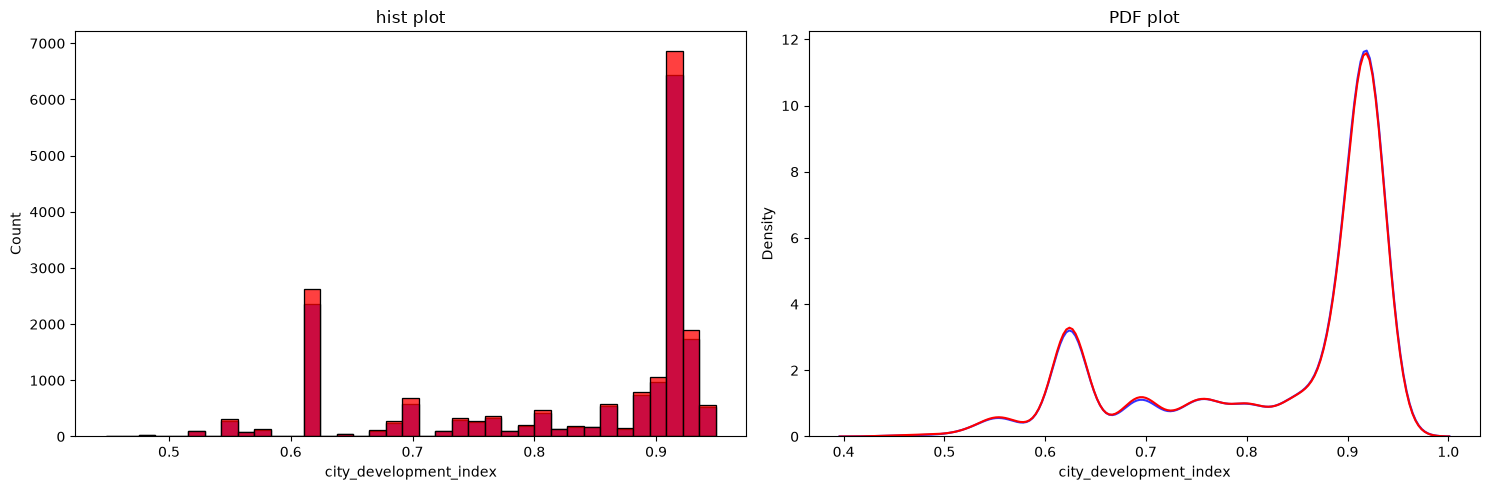

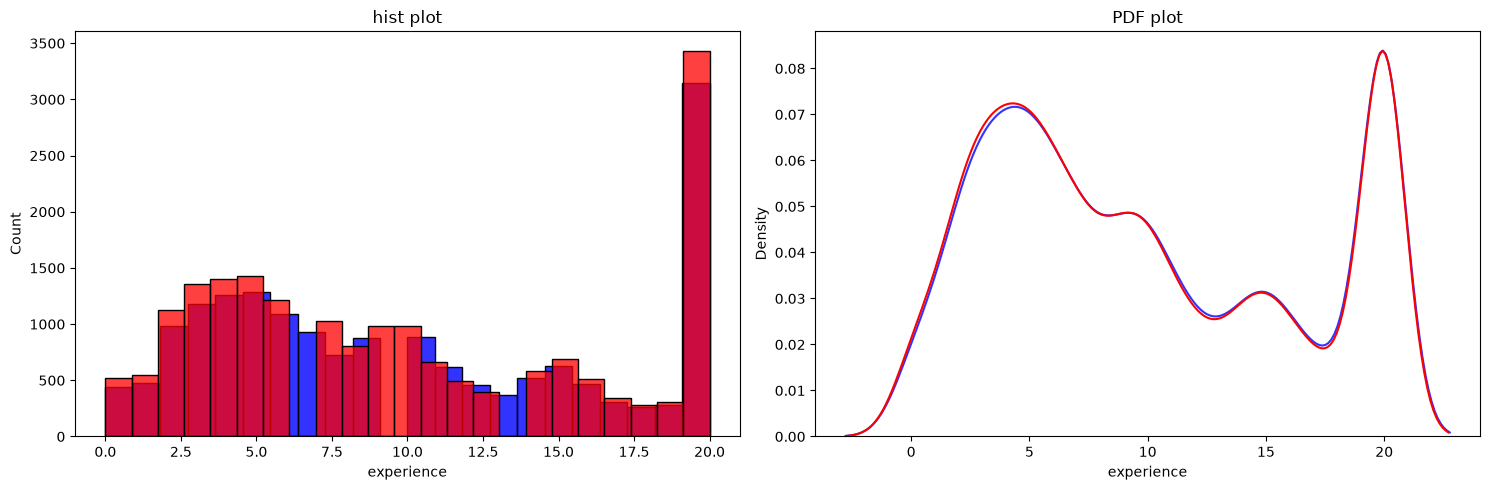

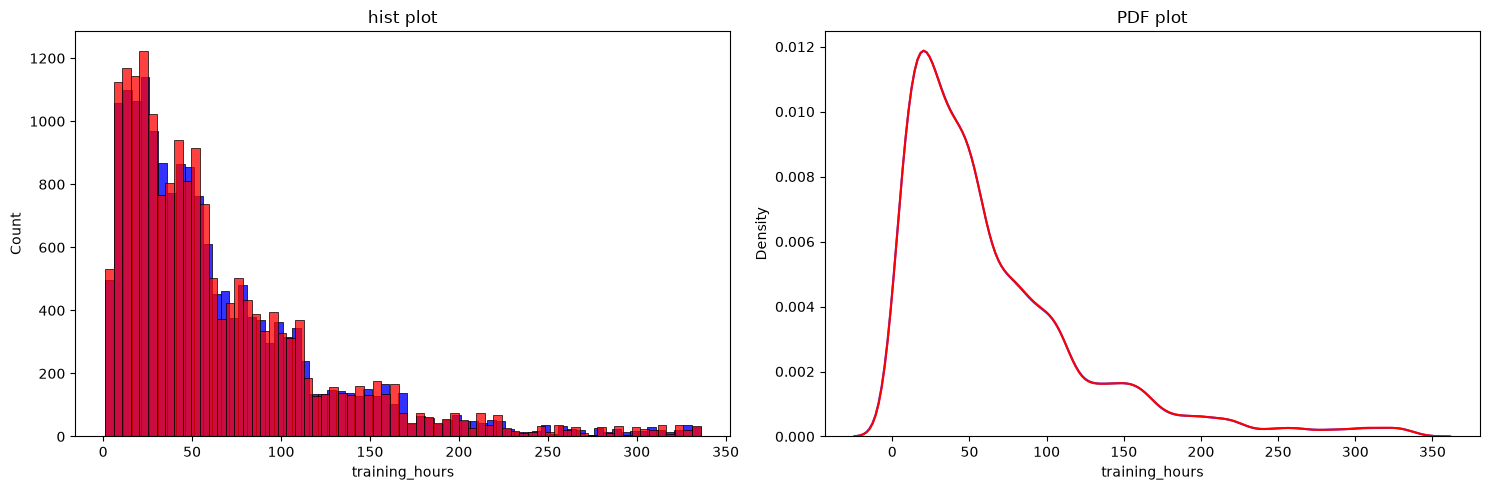

In [14]:
for col in cols:
    fig, ax = plt.subplots(1, 2, figsize = (15, 5))

    sns.histplot(new_df[col], ax= ax[0], color = 'blue', alpha = 0.8)
    sns.histplot(df[col], ax= ax[0], color = 'red')
    ax[0].set_title('hist plot')

    sns.kdeplot(new_df[col], ax= ax[1], color = 'blue', alpha = 0.8)
    sns.kdeplot(df[col], ax= ax[1], color = 'red')
    ax[1].set_title('PDF plot')

    plt.tight_layout()

In [15]:
new_df.head()

,city_development_index,enrolled_university,education_level,experience,training_hours
0,0.920,no_enrollment,Graduate,20.0,36.0
1,0.776,no_enrollment,Graduate,15.0,47.0
2,0.624,Full time course,Graduate,5.0,83.0
4,0.767,no_enrollment,Masters,20.0,8.0
5,0.764,Part time course,Graduate,11.0,24.0


<Axes: xlabel='enrolled_university'>

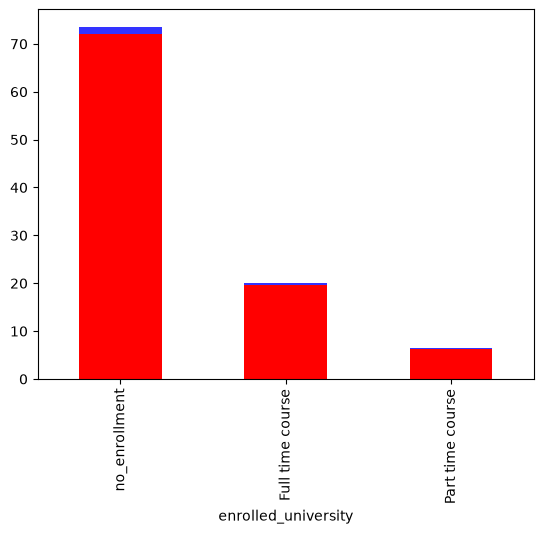

In [16]:
((new_df['enrolled_university'].value_counts() / new_df.shape[0]) * 100).plot(kind = 'bar', color = 'blue', alpha = 0.8)
((df['enrolled_university'].value_counts() / df.shape[0]) * 100).plot(kind = 'bar', color = 'red')

In [17]:
cols = [col for col in new_df.columns if (not (str(new_df[col].dtype).startswith('float')))]

In [18]:
cols

['enrolled_university', 'education_level']

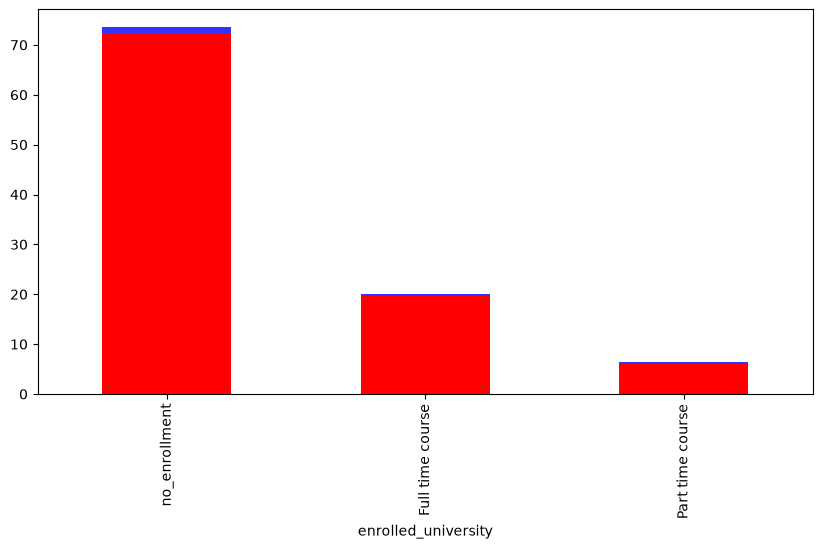

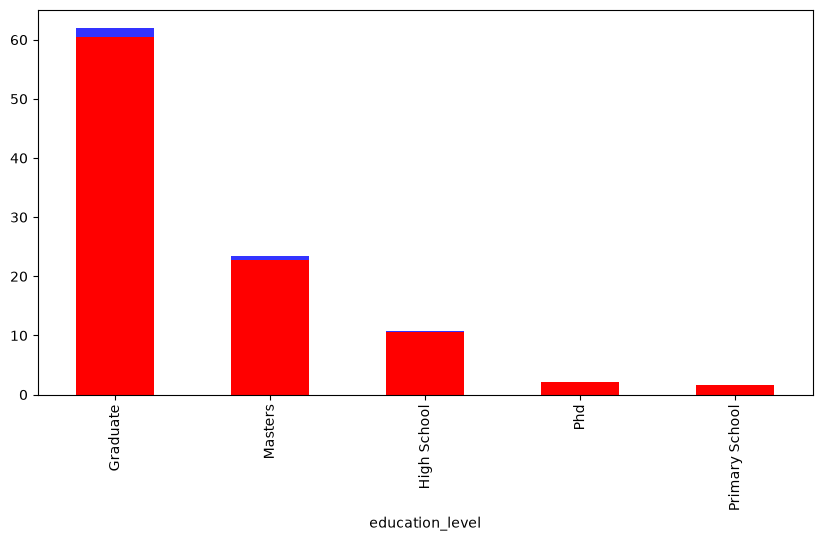

In [19]:
for col in cols:
    plt.figure(figsize=(10, 5))
    ((new_df[col].value_counts() / new_df.shape[0]) * 100).plot(kind = 'bar', color = 'blue', alpha = 0.8)
    ((df[col].value_counts() / df.shape[0]) * 100).plot(kind = 'bar', color = 'red')

In [44]:
for col in cols:
    temp = pd.concat([((new_df[col].value_counts() / new_df.shape[0]) * 100), 
    ((df[col].value_counts() / df.shape[0]) * 100)], axis= 1)
    temp.columns = ['cca', 'orignal']
    print(temp)

                           cca    orignal
enrolled_university                      
no_enrollment        73.518799  72.121307
Full time course     20.073333  19.610607
Part time course      6.407869   6.253262
                       cca    orignal
education_level                      
Graduate         61.983471  60.538678
Masters          23.408218  22.763336
High School      10.737982  10.528239
Phd               2.211617   2.160977
Primary School    1.658713   1.607683
